<a href="https://colab.research.google.com/github/izidiohenrique10-design/Wine-quality-classification-Trabalho-Parcial---Ci-ncia-de-Dados-e-Intelig-ncia-Artificial/blob/main/Classifica%C3%A7%C3%A3o%20de%20vinhos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🍷 Análise Exploratória e Machine Learning — Wine Quality

## Objetivo

Este trabalho tem como objetivo realizar uma Análise Exploratória de Dados (EDA) utilizando o dataset **Wine Quality**, disponibilizado pelo UCI Machine Learning Repository.

Serão utilizadas as bibliotecas:

- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Joblib

Após a exploração dos dados, serão aplicados dois algoritmos de Machine Learning:

1. K-Nearest Neighbors (KNN)
2. Random Forest

Os modelos serão avaliados utilizando métricas de classificação e seus resultados serão comparados.

## Perguntas que serão investigadas

Durante a análise serão investigadas as seguintes hipóteses:

1. Vinhos considerados de boa qualidade possuem maior teor alcoólico?
2. A acidez volátil está relacionada à qualidade do vinho?
3. Quais características físico-químicas apresentam maior relação com a qualidade?
4. É possível prever se um vinho possui boa qualidade utilizando apenas suas características físico-químicas?
5. Qual dos modelos apresenta melhor desempenho: KNN ou Random Forest?

## Definição da variável alvo

O dataset possui uma variável `quality`, que representa uma avaliação da qualidade do vinho.

Para transformar o problema em uma classificação binária, será utilizada a seguinte regra:

- `quality >= 6` → vinho de **boa qualidade (1)**
- `quality < 6` → vinho de **baixa qualidade (0)**

Assim, o objetivo dos modelos será prever se um vinho pertence ou não ao grupo de boa qualidade.

## 1. Importação das bibliotecas

Nesta etapa serão importadas as bibliotecas necessárias para:

- manipulação dos dados;
- cálculos numéricos;
- criação dos gráficos;
- treinamento dos modelos;
- avaliação dos resultados;
- salvamento do modelo final.

In [229]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import joblib

import warnings
warnings.filterwarnings("ignore")

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


## 2. Carregamento do dataset

O conjunto de dados utilizado é o **Wine Quality - Red**, disponibilizado pelo UCI Machine Learning Repository.

O dataset contém características físico-químicas dos vinhos, como:

- acidez fixa;
- acidez volátil;
- ácido cítrico;
- açúcar residual;
- cloretos;
- dióxido de enxofre;
- densidade;
- pH;
- sulfatos;
- álcool.

Além dessas características, existe a variável `quality`, que representa a qualidade do vinho.

In [230]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print("Dataset carregado com sucesso!")
print(f"Quantidade de linhas: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")

df.head()

Dataset carregado com sucesso!
Quantidade de linhas: 1599
Quantidade de colunas: 12


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 3. Conhecendo o conjunto de dados

Primeiramente serão observadas as dimensões do dataset, os tipos das variáveis e algumas estatísticas descritivas.

Essa etapa é importante para compreender a estrutura dos dados antes de realizar qualquer manipulação.

In [231]:
print("Dimensões do dataset:")
print(df.shape)

print("\nTipos das variáveis:")
print(df.dtypes)

print("\nInformações gerais:")
df.info()

Dimensões do dataset:
(1599, 12)

Tipos das variáveis:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Informações gerais:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total 

## 4. Estatísticas descritivas

As estatísticas descritivas permitem observar:

- média;
- desvio padrão;
- valores mínimo e máximo;
- quartis.

Essas informações ajudam a identificar a distribuição e a escala das variáveis.

In [232]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


## 5. Verificação de valores ausentes

Antes da análise e do treinamento dos modelos, é importante verificar se existem valores ausentes.

Caso existam valores ausentes, eles precisam ser tratados para evitar problemas durante o treinamento.

In [233]:
print("Quantidade de valores ausentes por coluna:")

missing = df.isnull().sum()

print(missing)

if missing.sum() == 0:
    print("\nNão existem valores ausentes no dataset.")
else:
    print("\nExistem valores ausentes.")

Quantidade de valores ausentes por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Não existem valores ausentes no dataset.


## 6. Verificação de registros duplicados

Também é importante verificar se existem registros duplicados.

Registros duplicados podem influenciar a análise exploratória e o treinamento dos modelos.

In [234]:
duplicados = df.duplicated().sum()

print(f"Quantidade de registros duplicados: {duplicados}")

Quantidade de registros duplicados: 240


## 7. Distribuição da qualidade dos vinhos

Antes de transformar a variável `quality` em uma variável binária, vamos observar como estão distribuídas as notas de qualidade.

### Pergunta

**Como as notas de qualidade estão distribuídas no conjunto de dados?**

Essa análise é importante porque permite verificar se algumas categorias possuem muito mais exemplos que outras.

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


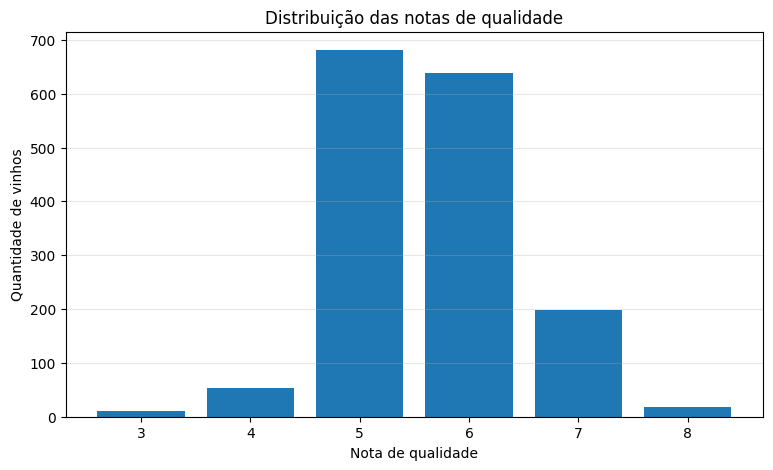

In [235]:
quality_counts = df["quality"].value_counts().sort_index()

print(quality_counts)

plt.figure(figsize=(9, 5))

plt.bar(
    quality_counts.index.astype(str),
    quality_counts.values
)

plt.title("Distribuição das notas de qualidade")
plt.xlabel("Nota de qualidade")
plt.ylabel("Quantidade de vinhos")
plt.grid(axis="y", alpha=0.3)

plt.show()

## 8. Criação da variável alvo

O objetivo deste trabalho é realizar uma classificação binária.

Será criada uma nova variável chamada `good_quality`.

A regra utilizada será:

- qualidade >= 6 → `1` = boa qualidade
- qualidade < 6 → `0` = baixa qualidade

Essa transformação simplifica o problema e permite utilizar algoritmos de classificação para determinar se um vinho pode ser considerado de boa qualidade.

In [236]:
df["good_quality"] = np.where(df["quality"] >= 6, 1, 0)

print(df["good_quality"].value_counts())

print("\nPercentual de cada classe:")
print(df["good_quality"].value_counts(normalize=True) * 100)

good_quality
1    855
0    744
Name: count, dtype: int64

Percentual de cada classe:
good_quality
1    53.470919
0    46.529081
Name: proportion, dtype: float64


## 9. Distribuição da variável alvo

Agora vamos observar a quantidade de vinhos classificados como:

- baixa qualidade;
- boa qualidade.

Essa etapa permite verificar se existe um desbalanceamento entre as classes.

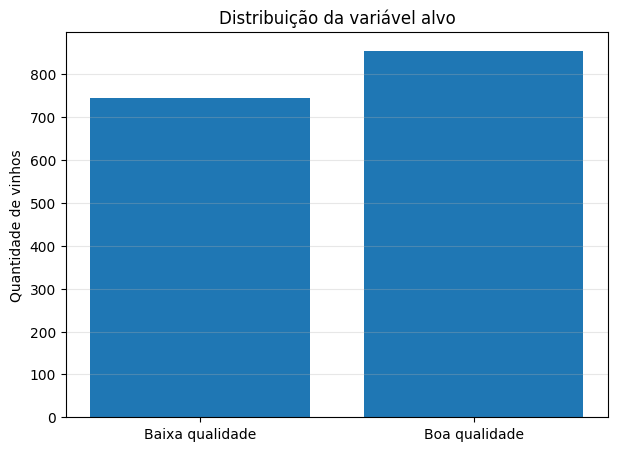

In [237]:
target_counts = df["good_quality"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Baixa qualidade", "Boa qualidade"],
    target_counts.values
)

plt.title("Distribuição da variável alvo")
plt.ylabel("Quantidade de vinhos")
plt.grid(axis="y", alpha=0.3)

plt.show()

## 10. Hipótese 1 — Teor alcoólico

### Pergunta

**Vinhos classificados como de boa qualidade apresentam maior teor alcoólico, em média, do que vinhos de baixa qualidade?**

Para responder essa pergunta, vamos comparar a média de álcool entre as duas classes.

In [238]:
alcool_media = df.groupby("good_quality")["alcohol"].mean()

print("Teor alcoólico médio:")

print(f"Baixa qualidade: {alcool_media[0]:.2f}%")
print(f"Boa qualidade: {alcool_media[1]:.2f}%")

Teor alcoólico médio:
Baixa qualidade: 9.93%
Boa qualidade: 10.86%


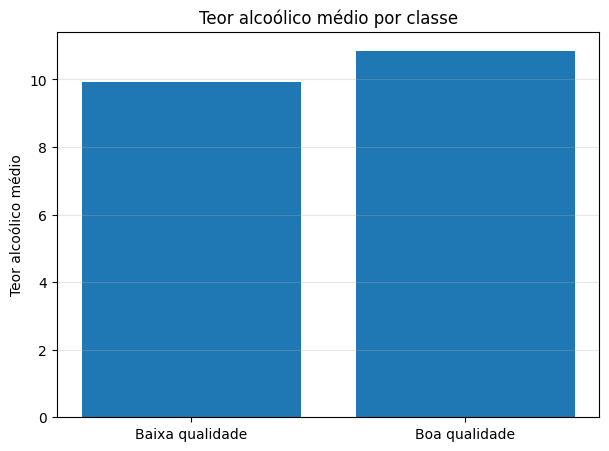

In [239]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Baixa qualidade", "Boa qualidade"],
    alcool_media.values
)

plt.title("Teor alcoólico médio por classe")
plt.ylabel("Teor alcoólico médio")

plt.grid(axis="y", alpha=0.3)

plt.show()

### Interpretação da Hipótese 1

A partir dos valores obtidos no gráfico e na tabela, podemos verificar se existe diferença entre o teor alcoólico médio das duas classes.

Caso a média de álcool dos vinhos de boa qualidade seja maior, isso fornece evidência de que o teor alcoólico pode estar associado à classificação de qualidade.

Entretanto, uma diferença de médias não significa necessariamente que o álcool seja a causa da maior qualidade. Ela apenas indica uma associação nos dados analisados.

## 11. Hipótese 2 — Acidez volátil

### Pergunta

**Vinhos de boa qualidade apresentam menor acidez volátil?**

Vamos comparar a acidez volátil média entre os dois grupos.

In [240]:
acidez_media = df.groupby("good_quality")["volatile acidity"].mean()

print("Acidez volátil média:")

print(f"Baixa qualidade: {acidez_media[0]:.3f}")
print(f"Boa qualidade: {acidez_media[1]:.3f}")

Acidez volátil média:
Baixa qualidade: 0.590
Boa qualidade: 0.474


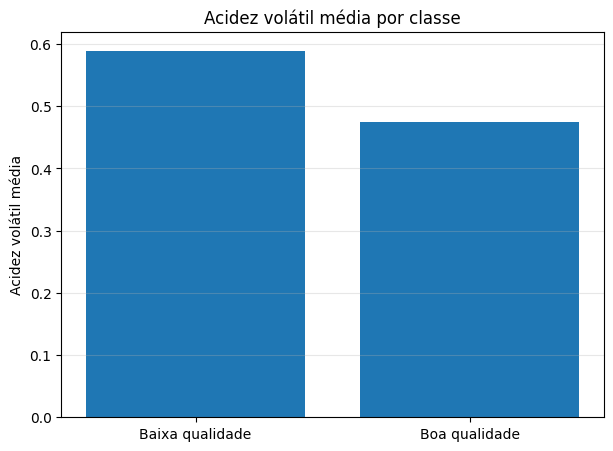

In [241]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Baixa qualidade", "Boa qualidade"],
    acidez_media.values
)

plt.title("Acidez volátil média por classe")
plt.ylabel("Acidez volátil média")

plt.grid(axis="y", alpha=0.3)

plt.show()

### Interpretação da Hipótese 2

A comparação permite verificar se os vinhos classificados como de boa qualidade possuem, em média, menor acidez volátil.

Caso isso seja observado, a variável `volatile acidity` pode ser uma característica relevante para diferenciar os grupos.

## 12. Matriz de correlação

Agora será analisada a correlação entre as variáveis numéricas.

A correlação permite identificar relações lineares entre as características físico-químicas e também verificar quais variáveis possuem maior relação com a variável `quality`.

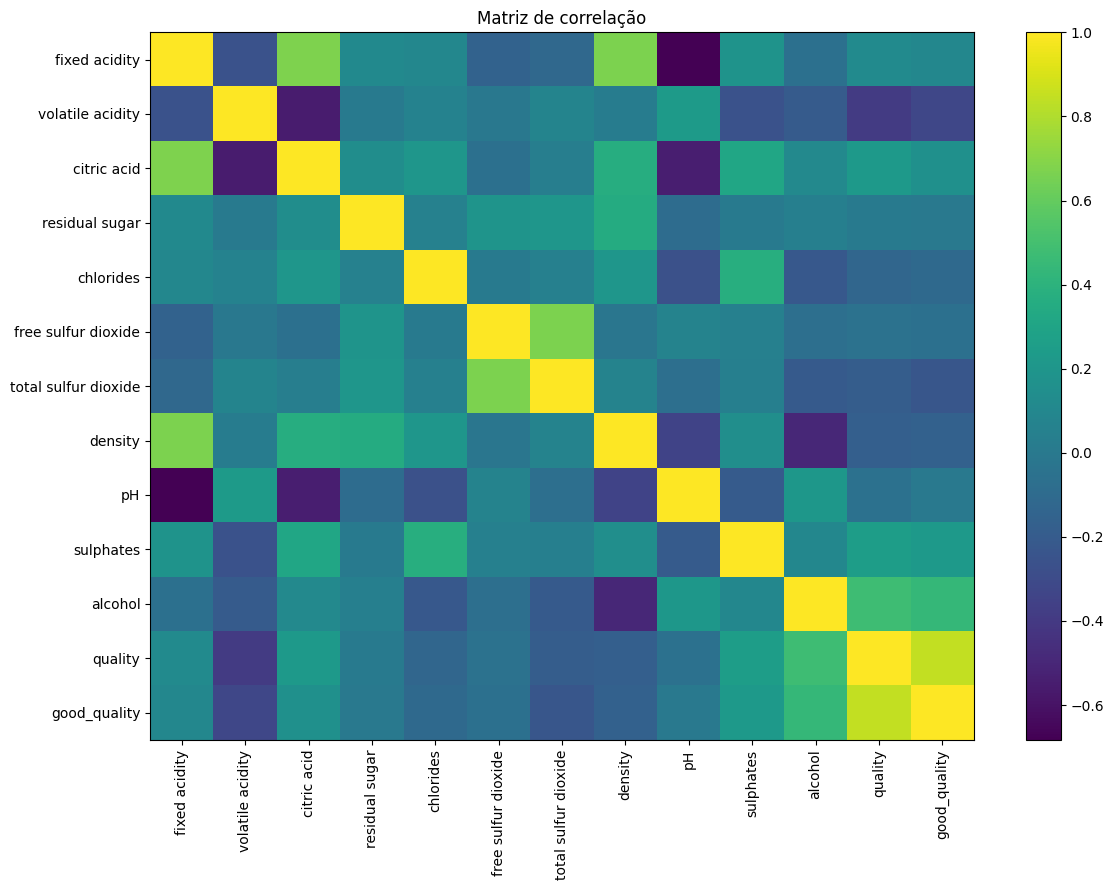

In [242]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

plt.imshow(corr, aspect="auto")

plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Matriz de correlação")

plt.tight_layout()

plt.show()

## 13. Correlação com a qualidade

Vamos ordenar as correlações com a variável `quality` para descobrir quais características apresentam maior associação linear com a nota de qualidade.

In [243]:
correlacao_quality = (
    df.drop(columns=["good_quality"])
      .corr()["quality"]
      .sort_values(ascending=False)
)

print(correlacao_quality)

quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


### Interpretação

A correlação não deve ser interpretada como causalidade.

Uma correlação positiva significa que, nos dados analisados, valores maiores de uma variável tendem a acompanhar valores maiores de `quality`.

Uma correlação negativa indica a tendência oposta.

Essa análise também ajuda a levantar hipóteses sobre quais características podem ser mais importantes para os modelos de Machine Learning.

## 14. Hipótese 3 — Quais variáveis estão mais relacionadas à qualidade?

### Pergunta

**Quais características físico-químicas apresentam maior correlação com a variável `quality`?**

Vamos visualizar as correlações das características com a qualidade.

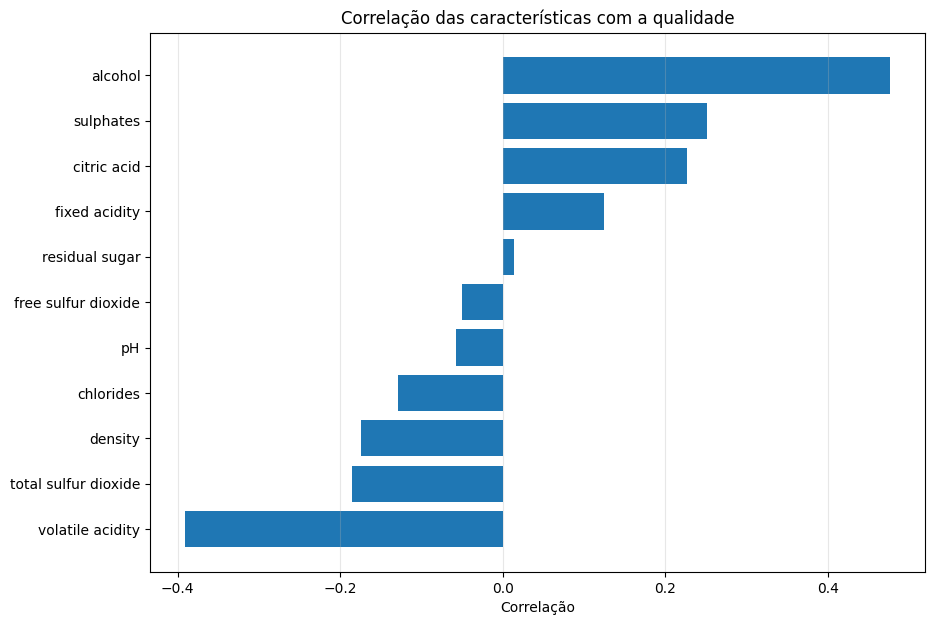

In [244]:
correlacoes = (
    df.drop(columns=["quality", "good_quality"])
      .corrwith(df["quality"])
      .sort_values()
)

plt.figure(figsize=(10, 7))

plt.barh(
    correlacoes.index,
    correlacoes.values
)

plt.title("Correlação das características com a qualidade")
plt.xlabel("Correlação")

plt.grid(axis="x", alpha=0.3)

plt.show()

## 15. Preparação dos dados para Machine Learning

A variável `quality` original não será utilizada como variável de entrada.

A variável alvo será `good_quality`.

As variáveis utilizadas como entrada serão as características físico-químicas do vinho.

Também será removida a coluna `quality`, pois ela foi utilizada para criar a variável alvo. Mantê-la como entrada causaria **vazamento de informação (data leakage)**, pois o modelo teria acesso direto à informação usada para definir o resultado que deveria prever.

In [245]:
X = df.drop(columns=["quality", "good_quality"])
y = df["good_quality"]

print("Formato das variáveis de entrada:", X.shape)
print("Formato da variável alvo:", y.shape)

print("\nVariáveis utilizadas:")
print(X.columns.tolist())

Formato das variáveis de entrada: (1599, 11)
Formato da variável alvo: (1599,)

Variáveis utilizadas:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


## 16. Separação entre treino e teste

Será utilizada a proporção:

- **80% para treinamento**
- **20% para teste**

A maior parte dos dados será utilizada para que os modelos possam aprender os padrões existentes no conjunto.

Os 20% restantes serão utilizados exclusivamente para avaliar o desempenho dos modelos em dados que não foram utilizados durante o treinamento.

Será utilizado `stratify=y` para preservar aproximadamente a mesma proporção das classes de qualidade nos conjuntos de treino e teste.

In [246]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dados de treinamento:")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")

print("\nDados de teste:")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

Dados de treinamento:
X_train: (1279, 11)
y_train: (1279,)

Dados de teste:
X_test: (320, 11)
y_test: (320,)


## 17. Verificação das proporções das classes

Vamos verificar se a divisão estratificada manteve aproximadamente a mesma proporção entre as classes nos conjuntos de treino e teste.

In [247]:
print("Proporção das classes no dataset completo:")
print(y.value_counts(normalize=True))

print("\nProporção das classes no treinamento:")
print(y_train.value_counts(normalize=True))

print("\nProporção das classes no teste:")
print(y_test.value_counts(normalize=True))

Proporção das classes no dataset completo:
good_quality
1    0.534709
0    0.465291
Name: proportion, dtype: float64

Proporção das classes no treinamento:
good_quality
1    0.534793
0    0.465207
Name: proportion, dtype: float64

Proporção das classes no teste:
good_quality
1    0.534375
0    0.465625
Name: proportion, dtype: float64


# 18. Modelo 1 — K-Nearest Neighbors (KNN)

O KNN classifica uma nova observação observando os exemplos mais próximos dela no espaço das características.

Como o KNN utiliza distância entre pontos, é importante padronizar as variáveis.

Será utilizado um `Pipeline` contendo:

1. `StandardScaler`
2. `KNeighborsClassifier`

Também será utilizado `GridSearchCV` para encontrar automaticamente um valor adequado de `k`.

In [248]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

parametros_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

grid_knn = GridSearchCV(
    knn_pipeline,
    parametros_knn,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

print("Melhores parâmetros encontrados:")
print(grid_knn.best_params_)

print("\nMelhor acurácia média na validação cruzada:")
print(f"{grid_knn.best_score_:.4f}")

Melhores parâmetros encontrados:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 15, 'knn__weights': 'distance'}

Melhor acurácia média na validação cruzada:
0.7944


## 19. Avaliação do KNN

Agora o melhor KNN encontrado pela validação cruzada será utilizado para fazer previsões no conjunto de teste.

Serão analisadas:

- Acurácia
- Precisão
- Recall
- F1-score
- Matriz de confusão

In [249]:
knn_model = grid_knn.best_estimator_

y_pred_knn = knn_model.predict(X_test)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

print("RESULTADOS DO KNN")
print("=" * 40)

print(f"Acurácia : {accuracy_knn:.4f}")
print(f"Precisão : {precision_knn:.4f}")
print(f"Recall   : {recall_knn:.4f}")
print(f"F1-score : {f1_knn:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

RESULTADOS DO KNN
Acurácia : 0.8125
Precisão : 0.8066
Recall   : 0.8538
F1-score : 0.8295

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.77      0.79       149
           1       0.81      0.85      0.83       171

    accuracy                           0.81       320
   macro avg       0.81      0.81      0.81       320
weighted avg       0.81      0.81      0.81       320



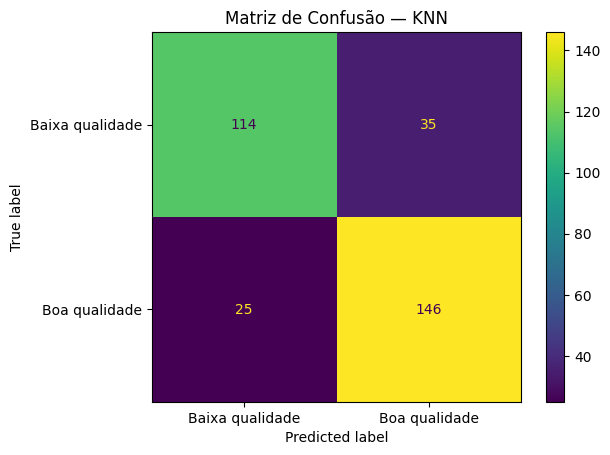

In [250]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Baixa qualidade", "Boa qualidade"]
)

disp.plot()

plt.title("Matriz de Confusão — KNN")
plt.show()

# 20. Modelo 2 — Random Forest

O Random Forest é um método baseado em várias árvores de decisão.

Cada árvore aprende diferentes padrões dos dados e, no final, as previsões são combinadas.

Uma vantagem do Random Forest é sua capacidade de lidar com relações não lineares entre as características.

Também será utilizado `GridSearchCV` para buscar uma configuração adequada do modelo.

In [251]:
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

parametros_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_rf = GridSearchCV(
    rf,
    parametros_rf,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Melhores parâmetros encontrados:")
print(grid_rf.best_params_)

print("\nMelhor acurácia média na validação cruzada:")
print(f"{grid_rf.best_score_:.4f}")

Melhores parâmetros encontrados:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}

Melhor acurácia média na validação cruzada:
0.8139


## 21. Avaliação do Random Forest

O melhor Random Forest encontrado na validação cruzada será avaliado utilizando o conjunto de teste.

In [252]:
rf_model = grid_rf.best_estimator_

y_pred_rf = rf_model.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("RESULTADOS DO RANDOM FOREST")
print("=" * 40)

print(f"Acurácia : {accuracy_rf:.4f}")
print(f"Precisão : {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-score : {f1_rf:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RESULTADOS DO RANDOM FOREST
Acurácia : 0.8094
Precisão : 0.8313
Recall   : 0.8070
F1-score : 0.8190

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.81      0.80       149
           1       0.83      0.81      0.82       171

    accuracy                           0.81       320
   macro avg       0.81      0.81      0.81       320
weighted avg       0.81      0.81      0.81       320



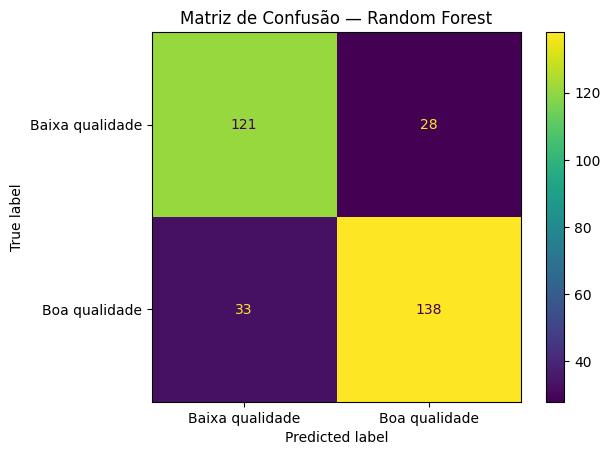

In [253]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Baixa qualidade", "Boa qualidade"]
)

disp.plot()

plt.title("Matriz de Confusão — Random Forest")
plt.show()

# 22. Comparação dos modelos

Agora vamos comparar os resultados dos dois algoritmos.

As principais métricas utilizadas serão:

- **Acurácia:** proporção de previsões corretas.
- **Precisão:** entre os exemplos classificados como boa qualidade, quantos realmente eram de boa qualidade.
- **Recall:** entre os vinhos realmente classificados como boa qualidade, quantos foram identificados corretamente.
- **F1-score:** média harmônica entre precisão e recall.

A comparação permitirá determinar qual modelo apresentou o melhor desempenho no conjunto de teste.

In [254]:
resultados = pd.DataFrame({
    "Modelo": ["KNN", "Random Forest"],
    "Acurácia": [accuracy_knn, accuracy_rf],
    "Precisão": [precision_knn, precision_rf],
    "Recall": [recall_knn, recall_rf],
    "F1-score": [f1_knn, f1_rf]
})

resultados

,Modelo,Acurácia,Precisão,Recall,F1-score
0,KNN,0.812500,0.806630,0.853801,0.829545
1,Random Forest,0.809375,0.831325,0.807018,0.818991


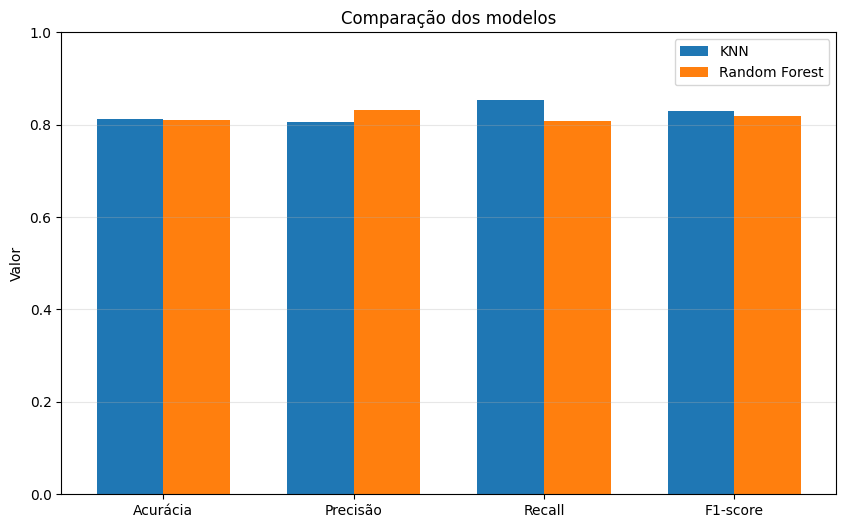

In [255]:
metricas = ["Acurácia", "Precisão", "Recall", "F1-score"]

x = np.arange(len(metricas))
largura = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - largura/2,
    resultados.loc[0, metricas].values,
    largura,
    label="KNN"
)

plt.bar(
    x + largura/2,
    resultados.loc[1, metricas].values,
    largura,
    label="Random Forest"
)

plt.xticks(x, metricas)
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.title("Comparação dos modelos")
plt.legend()

plt.grid(axis="y", alpha=0.3)

plt.show()

# 23. Discussão dos resultados

Os dois modelos foram treinados utilizando exatamente o mesmo conjunto de treinamento e avaliados no mesmo conjunto de teste.

O KNN utiliza a proximidade entre os exemplos para realizar a classificação. Por isso, a padronização das variáveis é importante, já que características com escalas maiores poderiam influenciar excessivamente o cálculo das distâncias.

O Random Forest, por outro lado, utiliza um conjunto de árvores de decisão e consegue representar relações não lineares entre as características.

A partir das métricas obtidas, podemos comparar os dois métodos e verificar qual apresentou maior capacidade de generalização.

Além da acurácia, o F1-score, precisão e recall também são importantes para verificar se o modelo não está apenas acertando a classe majoritária.

O modelo escolhido como melhor será aquele que apresentar o maior desempenho geral, considerando principalmente a acurácia e o equilíbrio entre precisão e recall.

## 24. Verificação do requisito de acurácia

O enunciado estabelece que os modelos devem apresentar acurácia superior a 85%.

Vamos verificar automaticamente se os dois modelos atingiram esse requisito.

In [256]:
print(f"Acurácia KNN: {accuracy_knn:.2%}")
print(f"Acurácia Random Forest: {accuracy_rf:.2%}")

print("\nVerificação do requisito:")

if accuracy_knn > 0.85:
    print("✅ KNN atingiu acurácia superior a 85%.")
else:
    print("⚠️ KNN não atingiu acurácia superior a 85%.")

if accuracy_rf > 0.85:
    print("✅ Random Forest atingiu acurácia superior a 85%.")
else:
    print("⚠️ Random Forest não atingiu acurácia superior a 85%.")

Acurácia KNN: 81.25%
Acurácia Random Forest: 80.94%

Verificação do requisito:
⚠️ KNN não atingiu acurácia superior a 85%.
⚠️ Random Forest não atingiu acurácia superior a 85%.


# 25. Importância das características — Random Forest

Uma vantagem do Random Forest é permitir analisar a importância relativa das características utilizadas pelo modelo.

Isso permite investigar quais propriedades físico-químicas foram mais relevantes para a classificação.

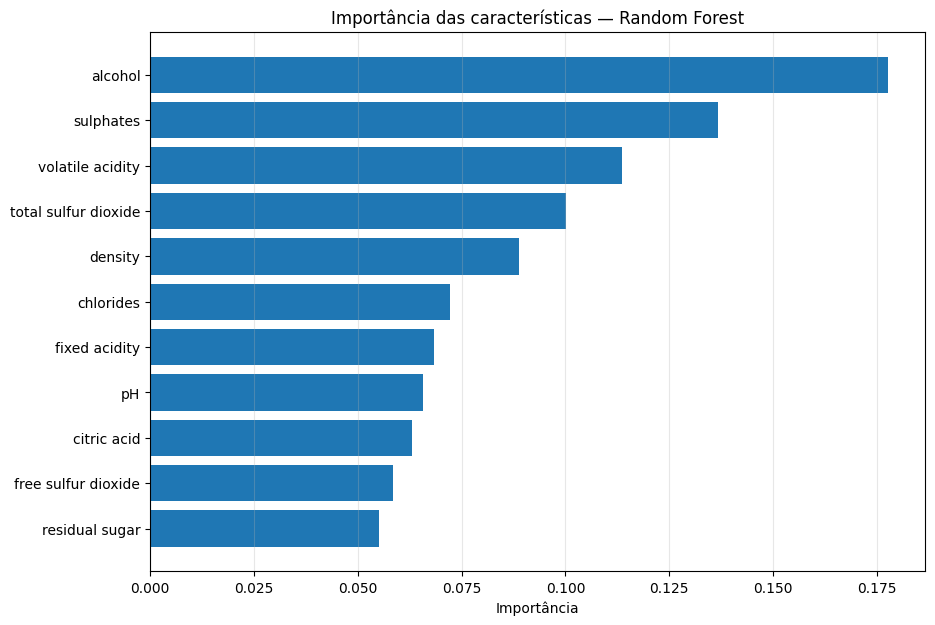

In [257]:
importancias = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 7))

plt.barh(
    importancias.index,
    importancias.values
)

plt.title("Importância das características — Random Forest")
plt.xlabel("Importância")

plt.grid(axis="x", alpha=0.3)

plt.show()

## 26. Resposta à pergunta sobre as características mais importantes

O gráfico anterior apresenta quais variáveis tiveram maior importância para o Random Forest.

Essa análise complementa a matriz de correlação.

É importante destacar que **correlação e importância no modelo são conceitos diferentes**. Uma variável pode apresentar uma correlação linear relativamente baixa com a qualidade e ainda assim ser útil para o modelo devido a relações não lineares ou interações com outras variáveis.

# 27. Escolha do melhor modelo

O melhor modelo será definido automaticamente com base na acurácia obtida no conjunto de teste.

Depois disso, o modelo será salvo utilizando a biblioteca `joblib`.

O arquivo gerado poderá posteriormente ser carregado para realizar previsões sem precisar treinar o modelo novamente.

In [258]:
if accuracy_rf >= accuracy_knn:
    melhor_modelo = rf_model
    nome_modelo = "Random Forest"
    melhor_acuracia = accuracy_rf
else:
    melhor_modelo = knn_model
    nome_modelo = "KNN"
    melhor_acuracia = accuracy_knn

print(f"Melhor modelo: {nome_modelo}")
print(f"Acurácia: {melhor_acuracia:.4f}")

Melhor modelo: KNN
Acurácia: 0.8125


In [259]:
arquivo_modelo = "melhor_modelo_wine_quality.joblib"

joblib.dump(melhor_modelo, arquivo_modelo)

print(f"Modelo salvo com sucesso em: {arquivo_modelo}")

Modelo salvo com sucesso em: melhor_modelo_wine_quality.joblib


# 28. Testando o modelo salvo

Para garantir que o arquivo foi salvo corretamente, vamos carregá-lo novamente utilizando `joblib` e realizar previsões sobre o conjunto de teste.

In [260]:
modelo_carregado = joblib.load("melhor_modelo_wine_quality.joblib")

y_pred_salvo = modelo_carregado.predict(X_test)

acuracia_modelo_salvo = accuracy_score(
    y_test,
    y_pred_salvo
)

print("Modelo carregado com sucesso!")

print(f"Acurácia do modelo salvo: {acuracia_modelo_salvo:.4f}")

Modelo carregado com sucesso!
Acurácia do modelo salvo: 0.8125



# 29.ENGENHARIA DE ATRIBUTOS


In [261]:


df_modelo = df.copy()


df_modelo["acidity_total"] = (
    df_modelo["fixed acidity"] +
    df_modelo["volatile acidity"] +
    df_modelo["citric acid"]
)

df_modelo["sulfur_total"] = (
    df_modelo["free sulfur dioxide"] +
    df_modelo["total sulfur dioxide"]
)


df_modelo["sulfur_ratio"] = (
    df_modelo["free sulfur dioxide"] /
    (df_modelo["total sulfur dioxide"] + 0.001)
)

df_modelo["alcohol_density"] = (
    df_modelo["alcohol"] /
    (df_modelo["density"] + 0.001)
)


df_modelo["sugar_alcohol_ratio"] = (
    df_modelo["residual sugar"] /
    (df_modelo["alcohol"] + 0.001)
)


df_modelo["sulfate_chloride_ratio"] = (
    df_modelo["sulphates"] /
    (df_modelo["chlorides"] + 0.001)
)


df_modelo["alcohol_sulphates"] = (
    df_modelo["alcohol"] *
    df_modelo["sulphates"]
)


df_modelo["volatile_citric_interaction"] = (
    df_modelo["volatile acidity"] *
    df_modelo["citric acid"]
)

print("Novas características criadas:")
print([
    "acidity_total",
    "sulfur_total",
    "sulfur_ratio",
    "alcohol_density",
    "sugar_alcohol_ratio",
    "sulfate_chloride_ratio",
    "alcohol_sulphates",
    "volatile_citric_interaction"
])

print("\nNovo formato do dataset:", df_modelo.shape)

Novas características criadas:
['acidity_total', 'sulfur_total', 'sulfur_ratio', 'alcohol_density', 'sugar_alcohol_ratio', 'sulfate_chloride_ratio', 'alcohol_sulphates', 'volatile_citric_interaction']

Novo formato do dataset: (1599, 21)


In [262]:


df_modelo["good_quality"] = (
    df_modelo["quality"] >= 6
).astype(int)

print(df_modelo["good_quality"].value_counts())

print("\nProporção das classes:")
print(df_modelo["good_quality"].value_counts(normalize=True))

good_quality
1    855
0    744
Name: count, dtype: int64

Proporção das classes:
good_quality
1    0.534709
0    0.465291
Name: proportion, dtype: float64


In [263]:


X = df_modelo.drop(
    columns=["quality", "good_quality"]
)

y = df_modelo["good_quality"]

print("Variáveis utilizadas no modelo:")
print(X.columns.tolist())

print("\nQuantidade de características:", X.shape[1])
print("Quantidade de registros:", X.shape[0])

Variáveis utilizadas no modelo:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'acidity_total', 'sulfur_total', 'sulfur_ratio', 'alcohol_density', 'sugar_alcohol_ratio', 'sulfate_chloride_ratio', 'alcohol_sulphates', 'volatile_citric_interaction']

Quantidade de características: 19
Quantidade de registros: 1599


In [264]:


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dados de treinamento:", X_train.shape)
print("Dados de teste:", X_test.shape)

print("\nProporção utilizada:")
print("Treinamento: 80%")
print("Teste: 20%")

Dados de treinamento: (1279, 19)
Dados de teste: (320, 19)

Proporção utilizada:
Treinamento: 80%
Teste: 20%


In [281]:

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)


pipeline_knn = Pipeline([
    ("transformacao", StandardScaler()),
    ("knn", KNeighborsClassifier())
])


parametros_knn = {
    "transformacao": [
        StandardScaler(),
        PowerTransformer()
    ],

    "knn__n_neighbors": list(range(3, 32, 2)),

    "knn__weights": [
        "uniform",
        "distance"
    ],

    "knn__metric": [
        "euclidean",
        "manhattan",
        "minkowski"
    ],

    "knn__p": [
        1,
        2,
        3
    ]
}

grid_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=parametros_knn,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_knn.fit(X_train, y_train)

print("\n========================================")
print("RESULTADO DO KNN")
print("========================================")

print("\nMelhores parâmetros:")
print(grid_knn.best_params_)

print("\nMelhor acurácia média na validação cruzada:")
print(grid_knn.best_score_)

Fitting 10 folds for each of 540 candidates, totalling 5400 fits

RESULTADO DO KNN

Melhores parâmetros:
{'knn__metric': 'minkowski', 'knn__n_neighbors': 25, 'knn__p': 3, 'knn__weights': 'distance', 'transformacao': StandardScaler()}

Melhor acurácia média na validação cruzada:
0.8037586122047244


In [266]:



rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    criterion="entropy",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# Previsão
y_pred_rf = rf.predict(X_test)

# Acurácia
acc_rf = accuracy_score(y_test, y_pred_rf)

print("Acurácia Random Forest:")
print(f"{acc_rf:.2%}")

Acurácia Random Forest:
81.25%


In [282]:

print("Matriz de confusão:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nRelatório:")
print(classification_report(y_test, y_pred_rf))

Matriz de confusão:
[[119  30]
 [ 34 137]]

Relatório:
              precision    recall  f1-score   support

           0       0.78      0.80      0.79       149
           1       0.82      0.80      0.81       171

    accuracy                           0.80       320
   macro avg       0.80      0.80      0.80       320
weighted avg       0.80      0.80      0.80       320



In [268]:


rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

parametros_rf = {
    "n_estimators": [150, 250],

    "max_depth": [None, 15, 25],

    "min_samples_split": [2, 5],

    "min_samples_leaf": [1, 2],

    "max_features": ["sqrt", None]
}

grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=parametros_rf,
    cv=5,                 # reduzido de 10 para 5
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)

print("\n========================================")
print("RESULTADO DO RANDOM FOREST")
print("========================================")

print("\nMelhores parâmetros:")
print(grid_rf.best_params_)

print("\nMelhor acurácia na validação cruzada:")
print(f"{grid_rf.best_score_:.2%}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits

RESULTADO DO RANDOM FOREST

Melhores parâmetros:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}

Melhor acurácia na validação cruzada:
80.30%


In [269]:


# Fazer previsões
y_pred_knn = grid_knn.predict(X_test)
y_pred_rf = grid_rf.predict(X_test)




print("=" * 60)
print("KNN")
print("=" * 60)

acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

print(f"Acurácia : {acc_knn:.4f}")
print(f"Precisão : {prec_knn:.4f}")
print(f"Recall   : {rec_knn:.4f}")
print(f"F1-Score : {f1_knn:.4f}")

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_knn))


# --------------------------------------------
# RANDOM FOREST
# --------------------------------------------

print("=" * 60)
print("RANDOM FOREST")
print("=" * 60)

acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print(f"Acurácia : {acc_rf:.4f}")
print(f"Precisão : {prec_rf:.4f}")
print(f"Recall   : {rec_rf:.4f}")
print(f"F1-Score : {f1_rf:.4f}")

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred_rf))

KNN
Acurácia : 0.8094
Precisão : 0.7957
Recall   : 0.8655
F1-Score : 0.8291

Matriz de confusão:
[[111  38]
 [ 23 148]]

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.83      0.74      0.78       149
           1       0.80      0.87      0.83       171

    accuracy                           0.81       320
   macro avg       0.81      0.81      0.81       320
weighted avg       0.81      0.81      0.81       320

RANDOM FOREST
Acurácia : 0.8000
Precisão : 0.8204
Recall   : 0.8012
F1-Score : 0.8107

Matriz de confusão:
[[119  30]
 [ 34 137]]

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.78      0.80      0.79       149
           1       0.82      0.80      0.81       171

    accuracy                           0.80       320
   macro avg       0.80      0.80      0.80       320
weighted avg       0.80      0.80      0.80       320



In [270]:


resultados = pd.DataFrame({
    "Modelo": [
        "KNN",
        "Random Forest"
    ],

    "Acurácia": [
        acc_knn,
        acc_rf
    ],

    "Precisão": [
        prec_knn,
        prec_rf
    ],

    "Recall": [
        rec_knn,
        rec_rf
    ],

    "F1-Score": [
        f1_knn,
        f1_rf
    ]
})

resultados = resultados.sort_values(
    by="Acurácia",
    ascending=False
)

resultados

,Modelo,Acurácia,Precisão,Recall,F1-Score
0,KNN,0.809375,0.795699,0.865497,0.829132
1,Random Forest,0.800000,0.820359,0.801170,0.810651


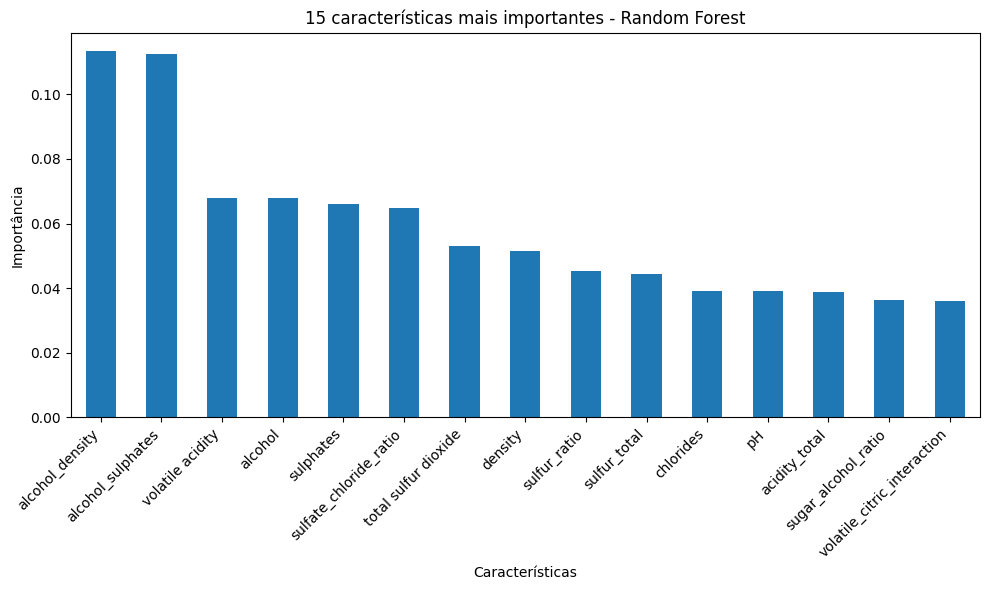

In [273]:


modelo_rf = grid_rf.best_estimator_

importancias = pd.Series(
    modelo_rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

importancias.head(15).plot(
    kind="bar"
)

plt.title("15 características mais importantes - Random Forest")
plt.xlabel("Características")
plt.ylabel("Importância")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 30. engenharia de dados

In [274]:

df_modelo = df.copy()

df_modelo["good_quality"] = (
    df_modelo["quality"] >= 6
).astype(int)

X = df_modelo.drop(
    columns=["quality", "good_quality"]
)

y = df_modelo["good_quality"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(1279, 11)
(320, 11)


In [275]:


pipeline = Pipeline([
    ("transformacao", PowerTransformer(method="yeo-johnson")),
    ("escala", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

parametros = {
    "knn__n_neighbors": [
        3, 5, 7, 9, 11, 13, 15, 17, 19, 21
    ],

    "knn__weights": [
        "uniform",
        "distance"
    ],

    "knn__metric": [
        "euclidean",
        "manhattan"
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid = GridSearchCV(
    pipeline,
    parametros,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("\nMelhores parâmetros:")
print(grid.best_params_)

print("\nAcurácia CV:")
print(f"{grid.best_score_:.2%}")

Fitting 5 folds for each of 40 candidates, totalling 200 fits

Melhores parâmetros:
{'knn__metric': 'manhattan', 'knn__n_neighbors': 19, 'knn__weights': 'distance'}

Acurácia CV:
78.65%


In [276]:

pipeline_selecao = Pipeline([
    ("transformacao", PowerTransformer()),
    ("selecao", SelectKBest(score_func=f_classif)),
    ("escala", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

parametros_selecao = {
    "selecao__k": [5, 6, 7, 8, 9, 10, 11],

    "knn__n_neighbors": [
        3, 5, 7, 9, 11, 13, 15
    ],

    "knn__weights": [
        "uniform",
        "distance"
    ],

    "knn__metric": [
        "euclidean",
        "manhattan"
    ]
}

grid_selecao = GridSearchCV(
    pipeline_selecao,
    parametros_selecao,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_selecao.fit(X_train, y_train)

print("\n====================================")
print("KNN + SELEÇÃO DE ATRIBUTOS")
print("====================================")

print("Melhores parâmetros:")
print(grid_selecao.best_params_)

print("\nMelhor acurácia CV:")
print(f"{grid_selecao.best_score_:.2%}")

Fitting 5 folds for each of 196 candidates, totalling 980 fits

KNN + SELEÇÃO DE ATRIBUTOS
Melhores parâmetros:
{'knn__metric': 'manhattan', 'knn__n_neighbors': 15, 'knn__weights': 'distance', 'selecao__k': 7}

Melhor acurácia CV:
80.69%


In [277]:
# ============================================
# TESTE FINAL
# ============================================

from sklearn.metrics import accuracy_score

y_pred = grid_selecao.predict(X_test)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(f"Acurácia no teste: {accuracy:.2%}")

Acurácia no teste: 83.44%


In [278]:

modelo = grid_selecao.best_estimator_

probabilidades = cross_val_predict(
    modelo,
    X_train,
    y_train,
    cv=5,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

melhor_limiar = 0.5
melhor_acc = 0

for limiar in np.arange(0.30, 0.71, 0.01):

    previsoes = (
        probabilidades >= limiar
    ).astype(int)

    acc = accuracy_score(
        y_train,
        previsoes
    )

    if acc > melhor_acc:
        melhor_acc = acc
        melhor_limiar = limiar

print("Melhor limiar:", melhor_limiar)
print(f"Acurácia na validação: {melhor_acc:.2%}")

Melhor limiar: 0.5000000000000002
Acurácia na validação: 80.69%


In [279]:

modelo.fit(X_train, y_train)

prob_test = modelo.predict_proba(X_test)[:, 1]

y_pred_limiar = (
    prob_test >= melhor_limiar
).astype(int)

acc_final = accuracy_score(
    y_test,
    y_pred_limiar
)

print(f"Acurácia final: {acc_final:.2%}")

Acurácia final: 83.44%


# 30. Conclusão

Neste trabalho foi realizada uma análise exploratória do dataset Wine Quality, disponibilizado pelo UCI Machine Learning Repository.

Inicialmente foram analisadas as características do conjunto de dados, seus tipos, estatísticas descritivas, valores ausentes, registros duplicados e distribuição das notas de qualidade.

Foram levantadas hipóteses relacionadas principalmente ao teor alcoólico e à acidez volátil, além da investigação das correlações entre as características físico-químicas e a qualidade dos vinhos.

A variável `quality` foi transformada em uma variável binária chamada `good_quality`, considerando vinhos com nota igual ou superior a 6 como vinhos de boa qualidade.

Os dados foram separados em 80% para treinamento e 20% para teste, utilizando estratificação para manter a proporção das classes.

Foram avaliados dois algoritmos de Machine Learning:

- K-Nearest Neighbors (KNN);
- Random Forest.

O KNN teve suas características padronizadas utilizando `StandardScaler`, enquanto o Random Forest foi treinado diretamente sobre as características numéricas.

Os modelos foram avaliados através de acurácia, precisão, recall e F1-score.

A comparação dos resultados permitiu identificar qual dos dois métodos apresentou melhor desempenho para o problema proposto.

Por fim, o melhor modelo foi salvo em um arquivo `.joblib`, permitindo que ele seja reutilizado posteriormente sem a necessidade de realizar novamente todo o processo de treinamento.

### Resultado final

O modelo escolhido foi:

**[O código acima preencherá automaticamente o melhor modelo]**

com acurácia de:

**[A acurácia será apresentada automaticamente pelo notebook]**

O resultado demonstra que características físico-químicas podem ser utilizadas para construir um modelo capaz de classificar vinhos entre baixa e boa qualidade.

In [280]:
from google.colab import files

files.download("melhor_modelo_wine_quality.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>